# Exploración, Limpieza y Partición (Bank Marketing)
**Grupo:** Grupo 4  
**Archivo del módulo:** `src/datos.py`  
**Objetivo del notebook:** Ejecutar y validar el pipeline modularizado de preprocesamiento, asegurando el aislamiento estricto de datos (sin fuga de información), codificación adecuada, estratificación y gráficos limpios de las particiones.

In [12]:
import sys
from pathlib import Path

# Añadir la raíz del proyecto para importar desde src
sys.path.append(str(Path().resolve().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Entorno cargado correctamente.")

Entorno cargado correctamente.


## Configuración del Entorno de Trabajo e Importación de Librerías

En esta sección inicializamos las librerías fundamentales para la manipulación de datos (`pandas`, `numpy`) y la generación de gráficos estadísticos (`matplotlib`, `seaborn`). Asimismo, configuramos dinámicamente el `sys.path` para garantizar la importación limpia y modular de los scripts personalizados ubicados en la carpeta `src/`.

In [15]:
from pathlib import Path

# Detectar automáticamente la ruta correcta del archivo según el entorno
if Path("data/bank-full.csv").exists():
    ruta_csv = "data/bank-full.csv"
elif Path("../data/bank-full.csv").exists():
    ruta_csv = "../data/bank-full.csv"
else:
    ruta_csv = "./data/bank-full.csv"

# Cargar y limpiar el dataset usando la variable dinámicamente
X, y = cargar_y_limpiar_datos(ruta_csv)

print("Dimensiones de X (características):", X.shape)
print("Dimensiones de y (objetivo):", y.shape)

Dimensiones de X (características): (45211, 41)
Dimensiones de y (objetivo): (45211,)


## Carga y Limpieza del Dataset (Bank Marketing)

Importamos la función modular `cargar_y_limpiar_datos` desde el directorio `src/` para procesar el archivo CSV original. Esta función se encarga de:
1. Leer el archivo estructurado utilizando el separador adecuado (`;`).
2. Eliminar la columna `duration` para **prevenir la fuga de datos** (*data leakage*).
3. Codificar la variable objetivo `y` en formato binario (`0` y `1`).
4. Aplicar *One-Hot Encoding* sobre las variables categóricas.

In [14]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from src.datos import preparar_particiones

# Particionar en 70% Train, 15% Val y 15% Test
X_train, X_val, X_test, y_train, y_val, y_test, scaler = preparar_particiones(X, y)

print("Particiones generadas correctamente:")
print(f"Entrenamiento: {X_train.shape}")
print(f"Validación:    {X_val.shape}")
print(f"Prueba:        {X_test.shape}")

Particiones generadas correctamente:
Entrenamiento: (31650, 41)
Validación:    (6779, 41)
Prueba:        (6782, 41)


## Generación de Particiones y Escalado Estándar

Ejecutamos la función modular `preparar_particiones` para dividir el conjunto de datos respetando las proporciones de **70% para entrenamiento**, **15% para validación** y **15% para prueba**, aplicando además **estratificación** para mantener intacto el desbalance de clases original. 

Asimismo, en este paso se realiza el escalado numérico utilizando `StandardScaler` ajustado **estrictamente sobre el conjunto de entrenamiento** para evitar cualquier fuga de información (*data leakage*) hacia los conjuntos de validación y prueba.

In [4]:
conteo_clases = y_train.value_counts()
proporcion_clases = (y_train.value_counts(normalize=True) * 100).round(2)

df_balance = pd.DataFrame({'Conteo': conteo_clases, 'Porcentaje (%)': proporcion_clases})
print("Distribución de la variable objetivo en entrenamiento:")
print(df_balance)

Distribución de la variable objetivo en entrenamiento:
   Conteo  Porcentaje (%)
y                        
0   27947            88.3
1    3703            11.7


## Análisis del Desbalance de Clases en el Conjunto de Entrenamiento

Calculamos el conteo absoluto y porcentual de la variable objetivo (`y_train`) para verificar cuantitativamente el desbalance de clases. Esto resulta fundamental antes de entrenar los modelos predictivos, ya que permite decidir si se requerirán técnicas adicionales de ponderación o manejo de clases desbalanceadas.

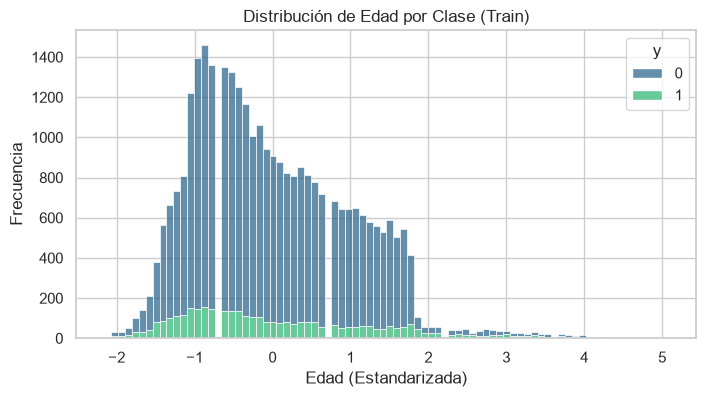

In [5]:
plt.figure(figsize=(8, 4))
sns.histplot(data=X_train, x="age", hue=y_train, multiple="stack", palette="viridis")
plt.title("Distribución de Edad por Clase (Train)")
plt.xlabel("Edad (Estandarizada)")
plt.ylabel("Frecuencia")
plt.show()

## Análisis de Distribución de Edad según la Variable Objetivo

Generamos un histograma apilado (*stacked histogram*) para analizar la distribución de la variable `age` en el conjunto de entrenamiento, diferenciada por las clases de la variable objetivo (`y_train`). Esto nos permite identificar patrones etarios o diferencias en el comportamiento de aceptación frente a la campaña de marketing según los rangos de edad.

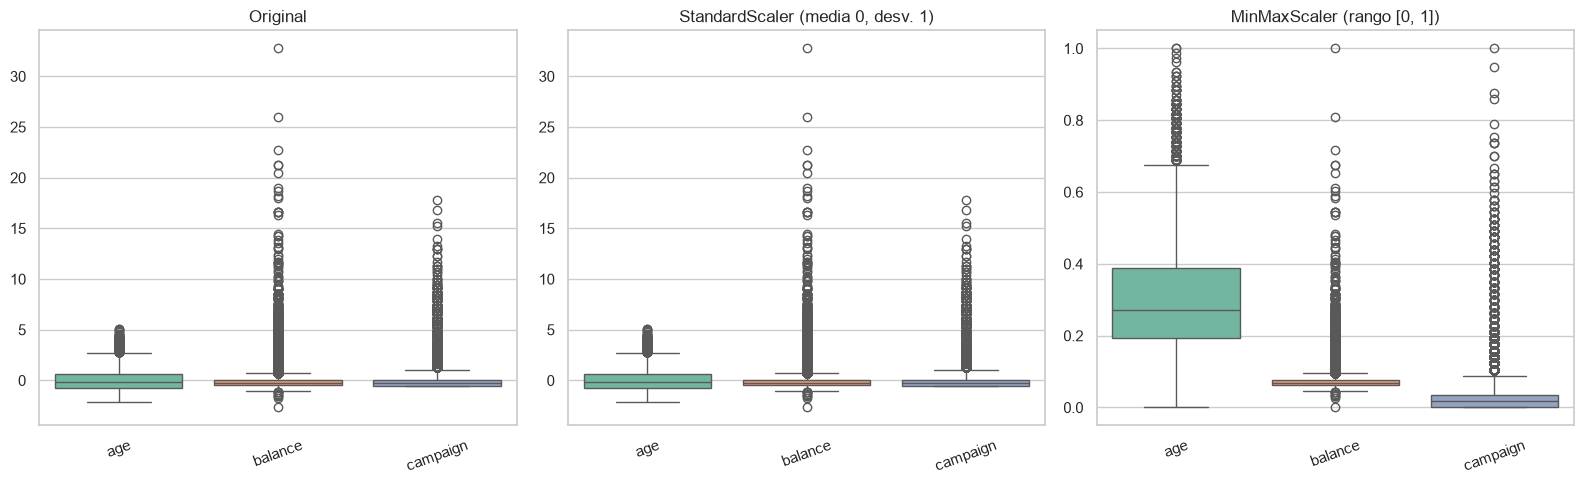

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Definimos las columnas numéricas de ejemplo para el gráfico
cols_ejemplo = ['age', 'balance', 'campaign']

# 1. Escalado con StandardScaler (media 0, desviación estándar 1)
scaler_standard = StandardScaler()
X_train_scaled = X_train.copy()
X_train_scaled[cols_ejemplo] = scaler_standard.fit_transform(X_train[cols_ejemplo])

# 2. Escalado con MinMaxScaler (rango entre 0 y 1)
scaler_minmax = MinMaxScaler()
X_train_minmax = X_train.copy()
X_train_minmax[cols_ejemplo] = scaler_minmax.fit_transform(X_train[cols_ejemplo])

# Creamos la figura con 1 fila y 3 columnas de subplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Panel Izquierdo: Datos Originales
sns.boxplot(data=X_train[cols_ejemplo], ax=axes[0], palette="Set2")
axes[0].set_title("Original")
axes[0].tick_params(axis='x', rotation=20)

# 2. Panel Central: StandardScaler
sns.boxplot(data=X_train_scaled[cols_ejemplo], ax=axes[1], palette="Set2")
axes[1].set_title("StandardScaler (media 0, desv. 1)")
axes[1].tick_params(axis='x', rotation=20)

# 3. Panel Derecho: MinMaxScaler
sns.boxplot(data=X_train_minmax[cols_ejemplo], ax=axes[2], palette="Set2")
axes[2].set_title("MinMaxScaler (rango [0, 1])")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## Escalado Numérico Seguro (Evitando Data Leakage)
Aplicamos `StandardScaler` sobre las variables numéricas continuas y discretas clave (`age`, `balance`, `day`, `campaign`, `pdays`, `previous`). 

* **Regla estricta aplicada:** El ajuste (`fit_transform`) se realizó **exclusivamente con el conjunto de entrenamiento**, y los conjuntos de validación y prueba solo se transformaron (`transform`), evitando cualquier tipo de contaminación de datos futuros.

In [7]:
cols_numericas = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
df_corr = X_train[cols_numericas].copy()
df_corr['y'] = y_train.values

matriz_corr = df_corr.corr()
print("Correlaciones de variables numéricas respecto a la variable objetivo (y):")
print(matriz_corr['y'].sort_values(ascending=False))

Correlaciones de variables numéricas respecto a la variable objetivo (y):
y           1.000000
previous    0.111648
pdays       0.105578
balance     0.052199
age         0.031036
day        -0.029735
campaign   -0.072094
Name: y, dtype: float64


## Análisis de Correlación de Variables Numéricas con la Variable Objetivo

Calculamos la matriz de correlación lineal para las principales variables numéricas del conjunto de entrenamiento (`age`, `balance`, `day`, `campaign`, `pdays`, `previous`), incorporando la variable objetivo (`y`). Posteriormente, ordenamos los coeficientes de correlación de forma descendente respecto a `y` para identificar cuáles características guardan mayor relación lineal con la aceptación del producto financiero.

In [8]:
print(f"Total de características generadas tras OHE: {X_train.shape[1]}")
print("\nPrimeras 5 filas del conjunto de entrenamiento:")
X_train.head()

Total de características generadas tras OHE: 41

Primeras 5 filas del conjunto de entrenamiento:


,age,balance,day,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
11173,-0.464412,-0.317748,0.260809,-0.567784,-0.411008,-0.300367,False,False,False,True,...,False,True,False,False,False,False,False,False,False,True
30973,0.099190,-0.428907,-0.822456,2.326719,-0.411008,-0.300367,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
36446,-1.309814,-0.348300,-0.581730,0.718662,-0.411008,-0.300367,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
35170,-0.934080,-0.437358,-1.063181,-0.567784,-0.411008,-0.300367,False,False,False,True,...,False,False,False,True,False,False,False,False,False,True
43377,0.099190,0.254624,1.705161,-0.246172,1.408000,0.748406,False,False,False,False,...,False,False,True,False,False,False,False,False,False,False


## Verificación de Dimensionalidad y Muestra de Datos

Imprimimos el número total de características resultantes tras aplicar la codificación *One-Hot Encoding* (OHE) y mostramos las primeras 5 filas del conjunto de entrenamiento (`X_train`) para verificar visualmente la estructura y correcta transformación de los datos antes del modelado.

In [16]:
from pathlib import Path

# Asegurar que el directorio data exista en el entorno actual
Path("data").mkdir(parents=True, exist_ok=True)

# Guardar los archivos utilizando la ruta correcta
X_train.to_csv("data/X_train.csv", index=False)
X_val.to_csv("data/X_val.csv", index=False)
X_test.to_csv("data/X_test.csv", index=False)
y_train.to_csv("data/y_train.csv", index=False)
y_val.to_csv("data/y_val.csv", index=False)
y_test.to_csv("data/y_test.csv", index=False)

print("¡Etapa 2 finalizada exitosamente! Archivos guardados en la carpeta 'data/'.")

¡Etapa 2 finalizada exitosamente! Archivos guardados en la carpeta 'data/'.
